# Apply bias adjustment to climate projection data

Every climate model shows a deviation from climatology, called bias. The procedure to correct or limit this error is called Bias Adjustment (BA).

Period 1950-1999 is used for training the model on ERA5, period 2000-2014 is used to test the model on the historical experiment of NEX-GDDP-CMIP6, then the adjustment is applied to scenario experiments for period 2024-2100.
A q-q plot is made to test the performance of the BA against the test set.

For the midterm discussion, a variation of Quantile Mapping (QM) approach is used, i.e. the Quantile Delta Mapping (QDM) algorithm, and it is applied to variables derived from `tas` and `pr`.

In [1]:
import importlib

import numpy
import xarray
import xclim.sdba

import plots
import settings
import thesis

# Workaround to reload settings if this block is executed a second time but notebook is not restarted.
try:
    id(flag_reload)
    flag_reload = importlib.reload(settings)
except NameError:  # Raised if `flag_reload` is not defined, hence when block is executed the first time.
    flag_reload = settings

In [2]:
nquantiles_training = 50
nquantiles_test = 20

dir_data = settings.dir_data / settings.location / "preprocessed"

dir_out = dir_data.parent / "adjusted"
dir_out.mkdir(parents=True, exist_ok=True)

In [3]:
chunks = {"latitude": 1, "longitude": 1, "time": -1}
ds_reference = xarray.open_dataset(dir_data / "reference.nc", chunks=chunks)

m = "EC-Earth3"  # Only model EC-Earth3 is used for the midterm discussion.

ds_historical = xarray.open_dataset(dir_data / f"historical_{m}.nc", chunks=chunks)

concat_dim = "scenario"
ds_scenario = xarray.open_mfdataset(
    [dir_data / f"{s}_{m}.nc" for s in thesis.scenario],
    chunks=chunks,
    concat_dim=concat_dim,
    combine="nested",
    combine_attrs="drop_conflicts"
)
ds_scenario = ds_scenario.assign_coords({concat_dim: list(thesis.scenario)})

# Collect all datasets in an iterator for programmatic access.
dict_dataset = {"reference": ds_reference, "historical": ds_historical}
dict_dataset.update({s: ds_scenario.loc[{concat_dim: s}].reset_coords(drop=True) for s in thesis.scenario})

# Collect all datasets in a single dataset for convenience in plotting.
e_dim = "experiment"
ds_data = xarray.concat(
    dict_dataset.values(),  # From Python 3.7 dict preserves order.
    e_dim,
    combine_attrs="drop_conflicts"
)
ds_data = ds_data.assign_coords({e_dim: list(dict_dataset.keys())})
ds_data = ds_data.chunk(chunks)

In [4]:
ba = {}  # Store data about the adjustment of selected variables.

## BA of daily temperature

First plot the time series of daily temperature.

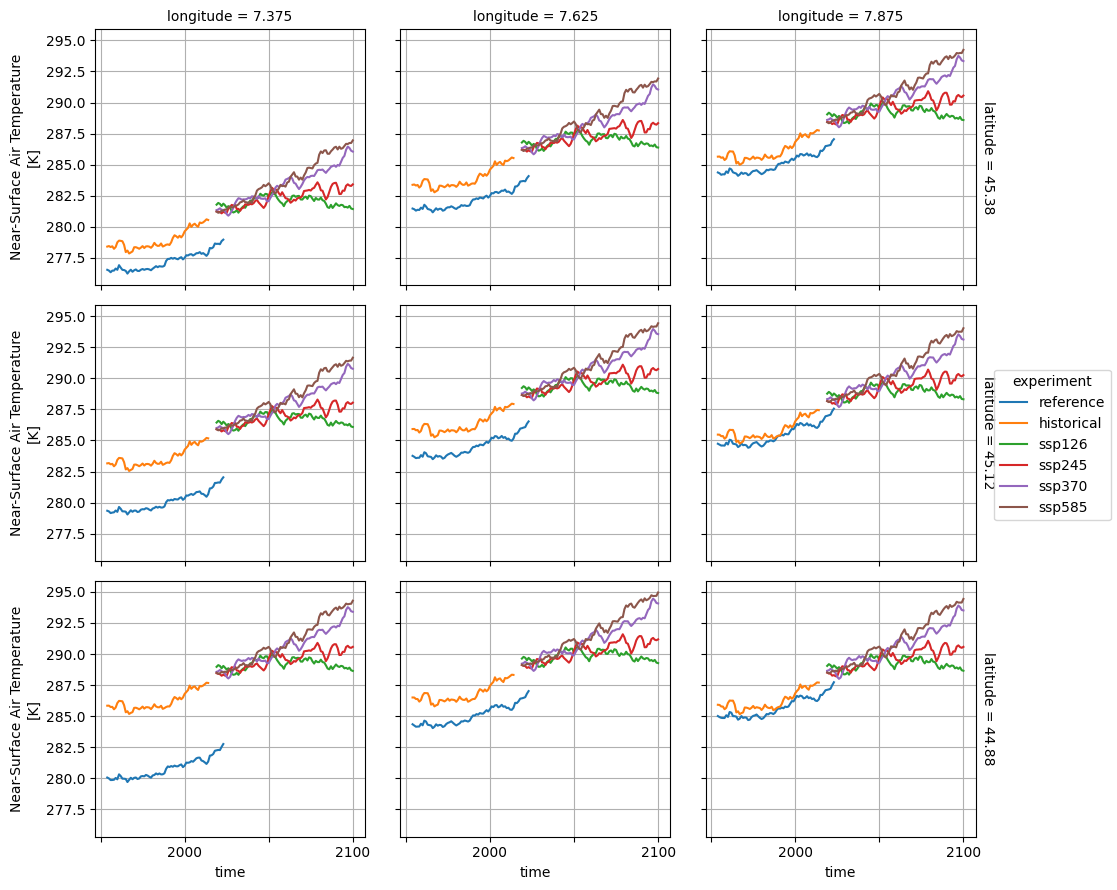

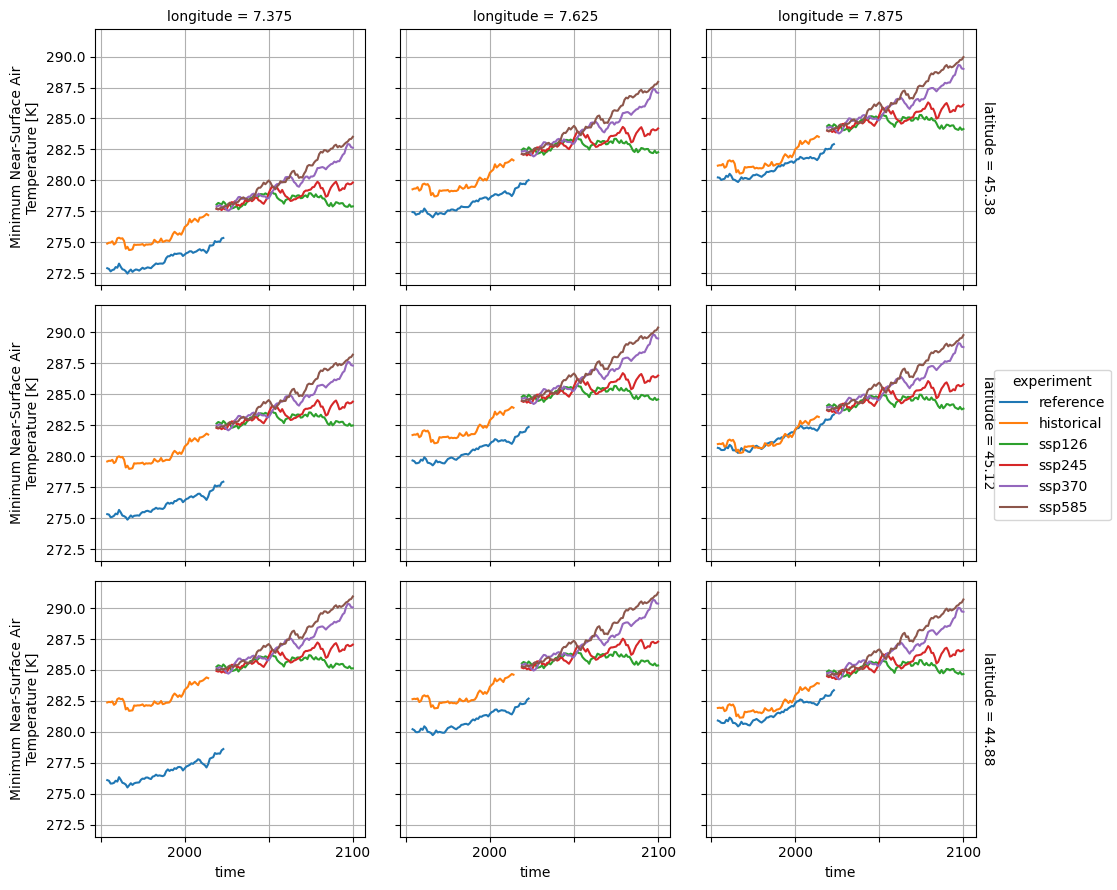

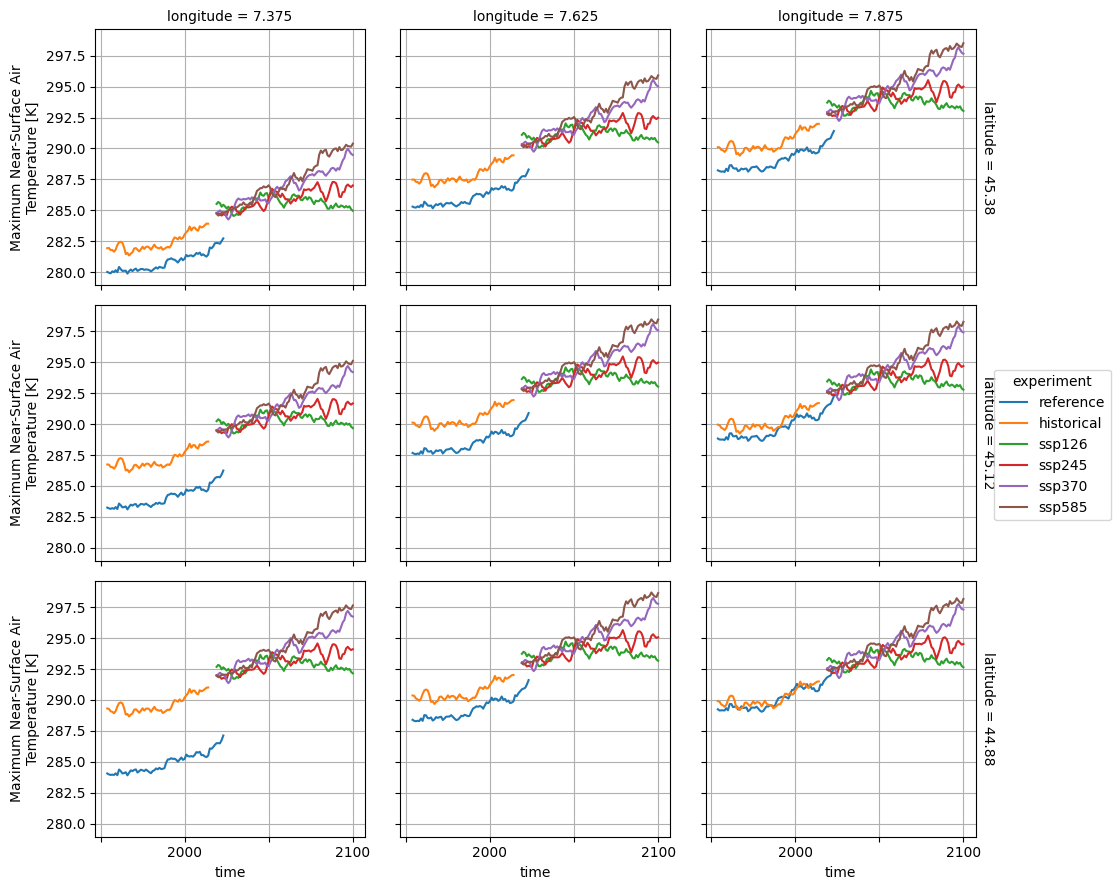

In [5]:
variables = ["tas", "tasmin", "tasmax"]
for v in variables:
    plots.yearly_mean_time_series_facet(ds_data[v], hue=e_dim, fname=f"adjusted_{v}_{m}_pre.pdf")

Then apply QDM, it is additive for temperature.

In [6]:
_da = {}
for v in variables:
    ba[v] = xclim.sdba.QuantileDeltaMapping.train(
        ds_data[v].sel({e_dim: "reference", "time": thesis.training_period}, drop=True),
        ds_data[v].sel({e_dim: "historical", "time": thesis.training_period}, drop=True),
        nquantiles=nquantiles_training,
        group="time",
        kind='+'
    )
    _da[v] = ba[v].adjust(ds_data[v])
    _da[v].name = v  # Overwrite the default name.
ds_adjusted = xarray.Dataset(data_vars=_da, attrs=ds_data.attrs)

# Insert the original reference, which is correct by definition.
ds_adjusted = ds_adjusted.drop_sel({e_dim: "reference"})
ds_adjusted = xarray.concat(
    (ds_adjusted, ds_data.sel({e_dim: "reference"})),
    e_dim
)

Plot the results of BA for temperature variables.

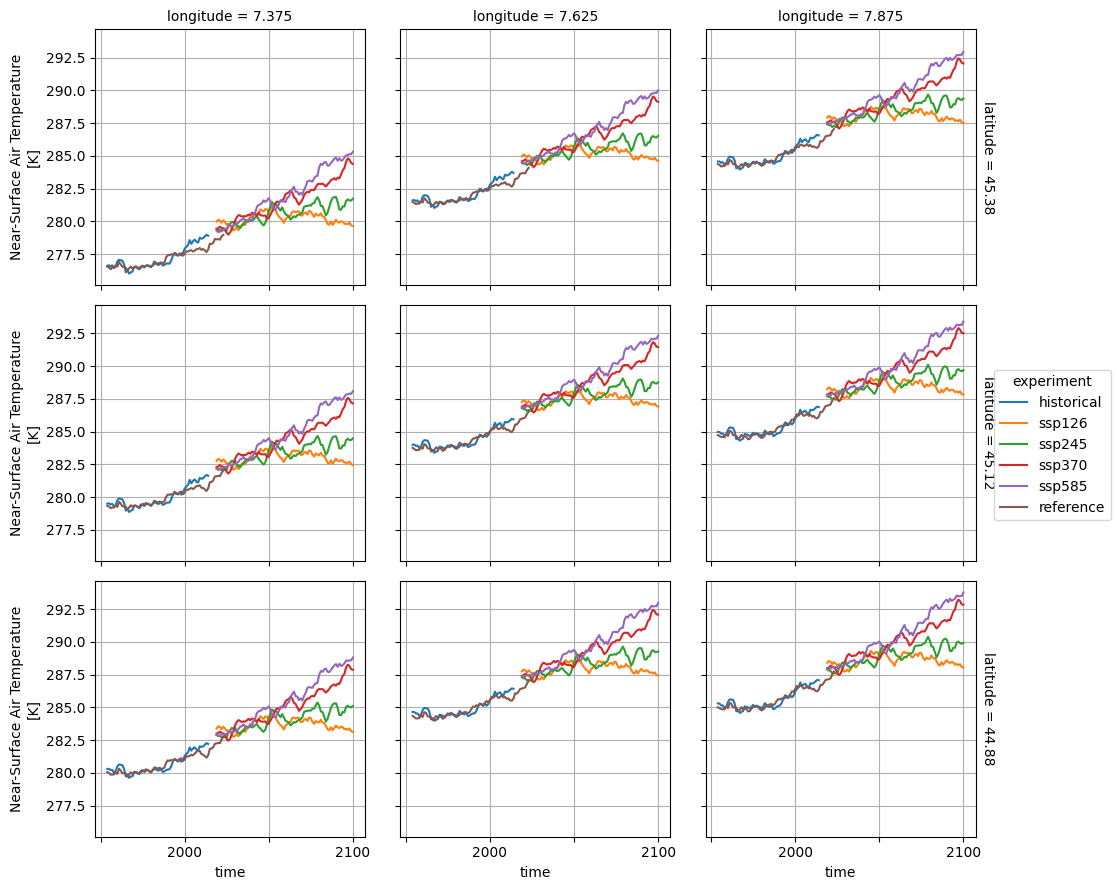

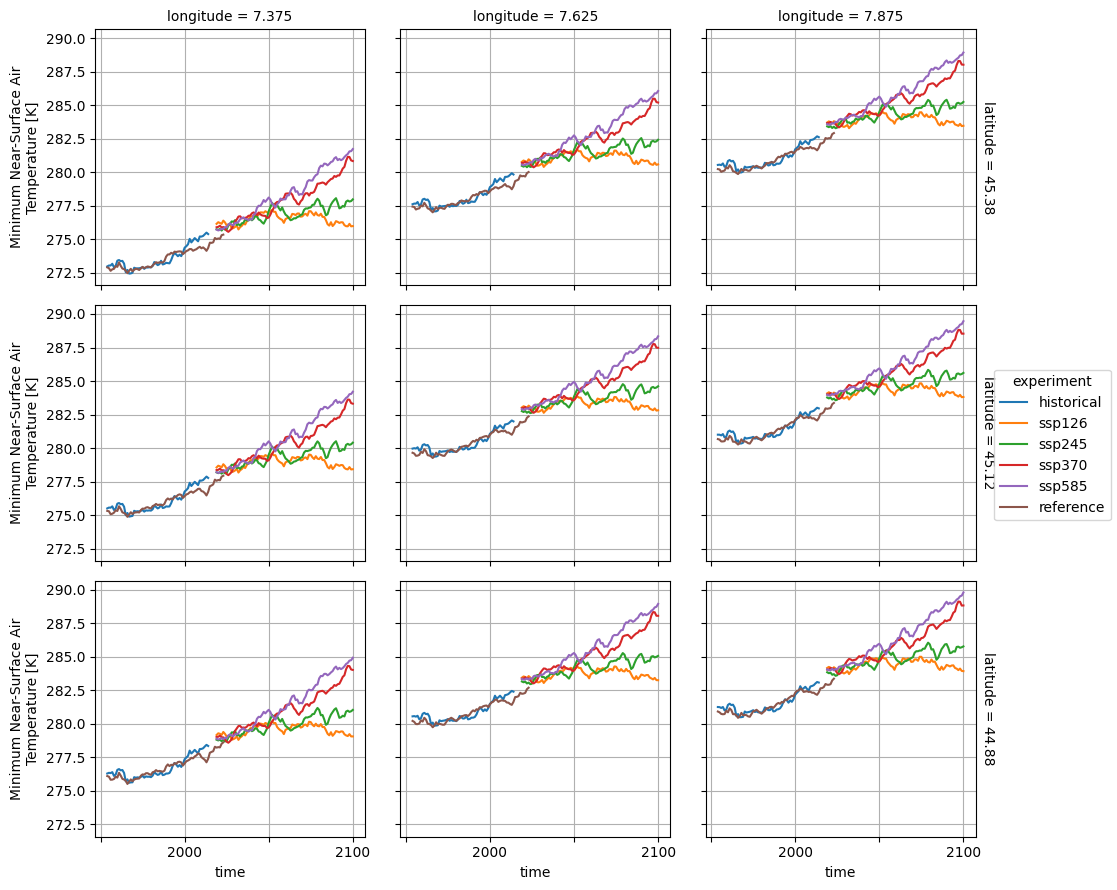

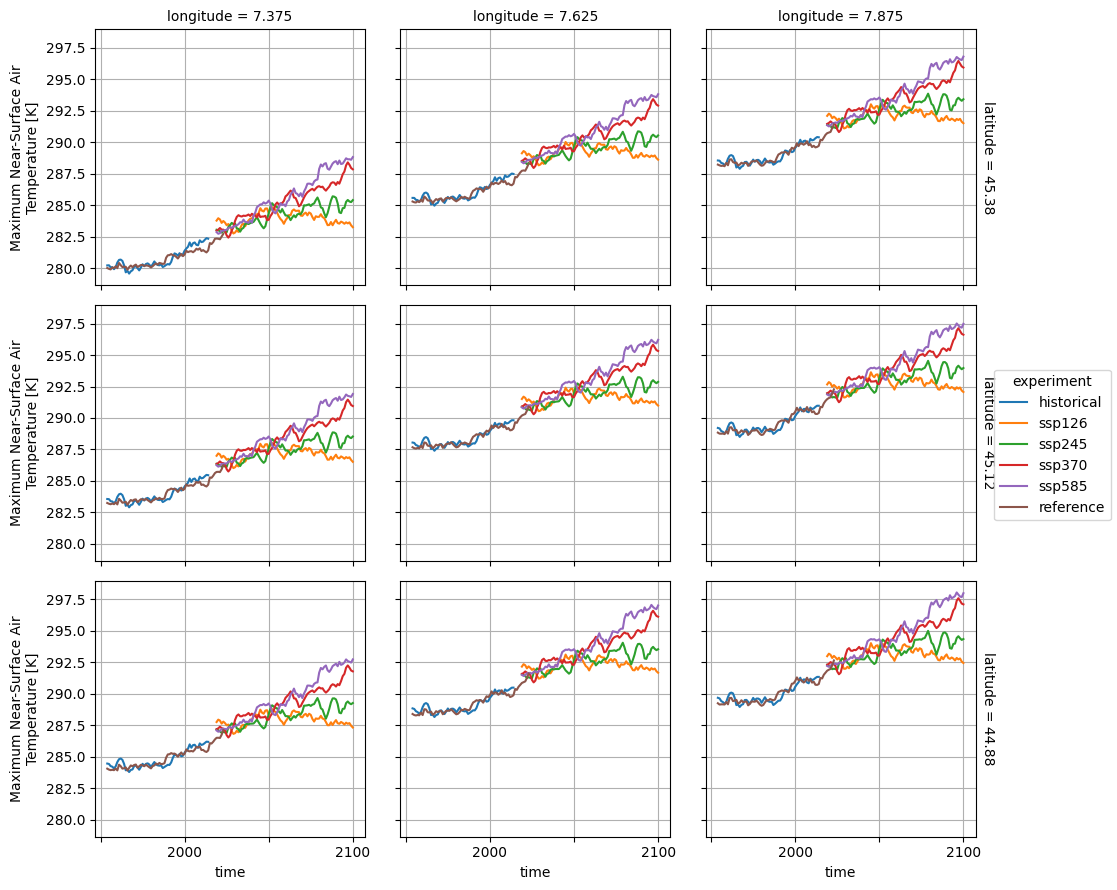

In [7]:
for v in variables:
    plots.yearly_mean_time_series_facet(ds_adjusted[v], hue=e_dim, fname=f"adjusted_{v}_{m}_post.pdf")

Compare pre and post BA time series visually.

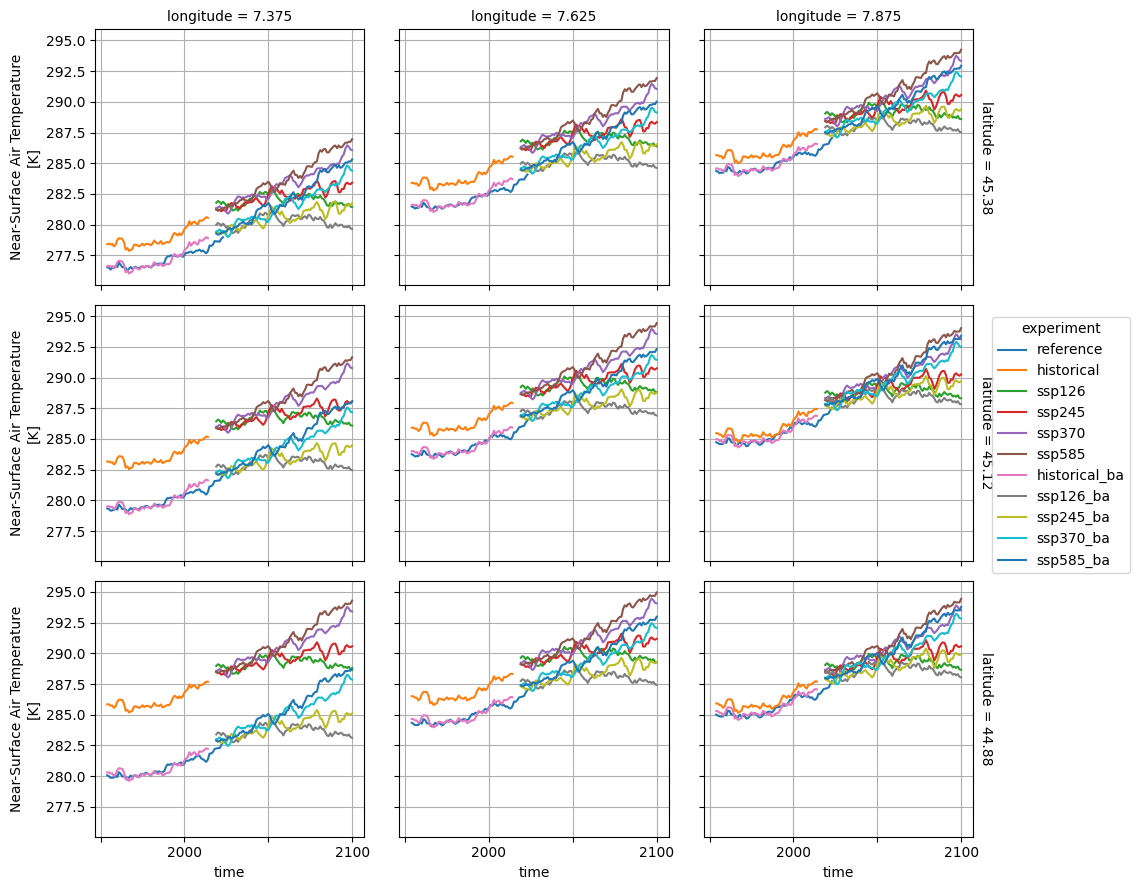

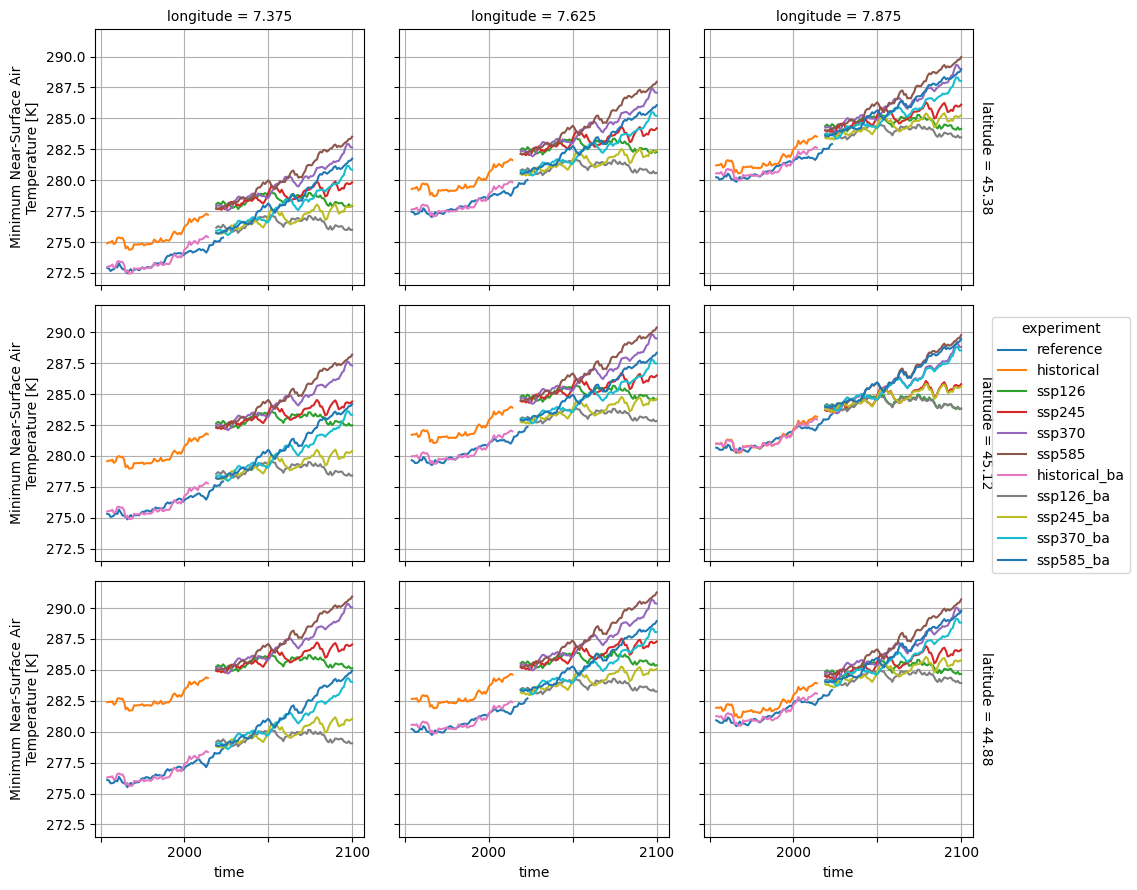

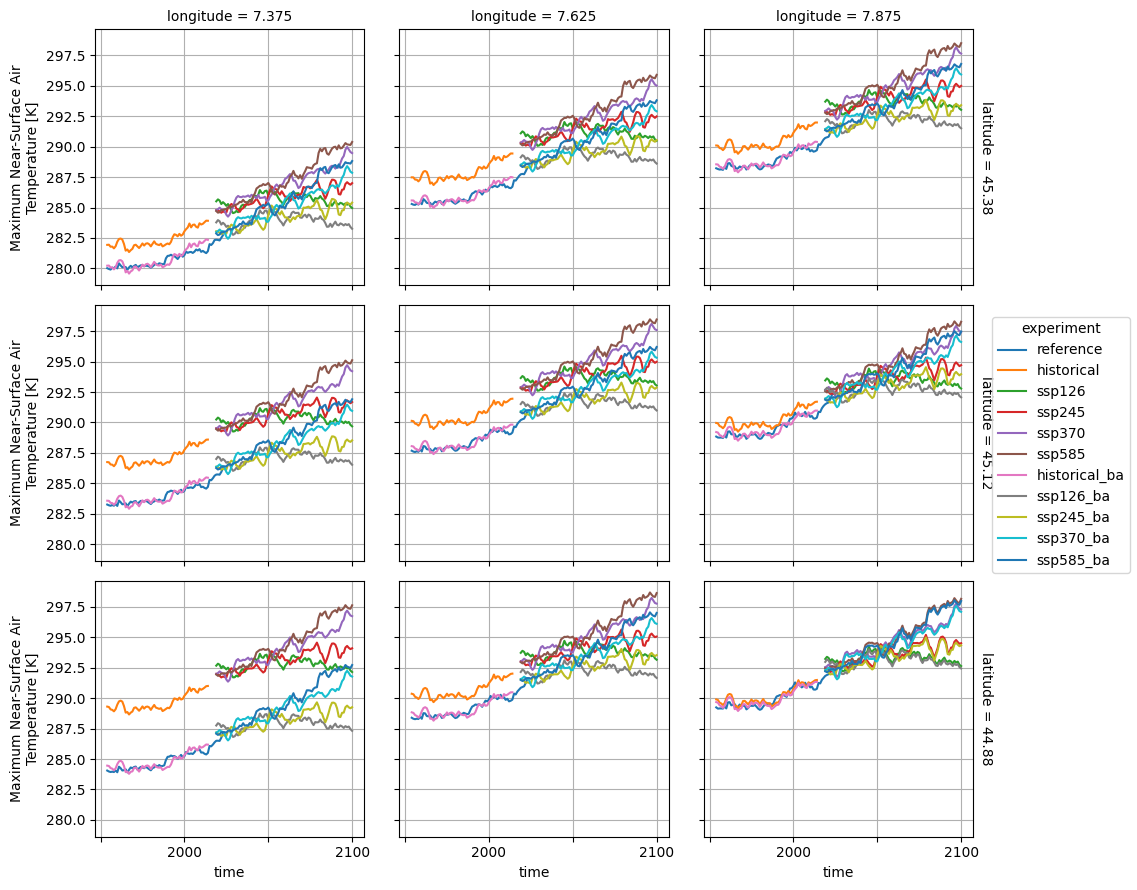

In [8]:
_ds = xarray.concat(
    (ds_data[variables], ds_adjusted[variables].assign_coords({e_dim: ds_adjusted[e_dim].str + "_ba"})),
    e_dim,
    combine_attrs="drop_conflicts"
)
_ds = _ds.drop_sel({e_dim: "reference_ba"})  # Do not plot same time series twice.
for v in variables:
    plots.yearly_mean_time_series_facet(_ds[v], hue=e_dim, fname=f"adjusted_{v}_{m}_prepost.pdf")

## BA of daily precipitation

First plot the time series of daily precipitation.

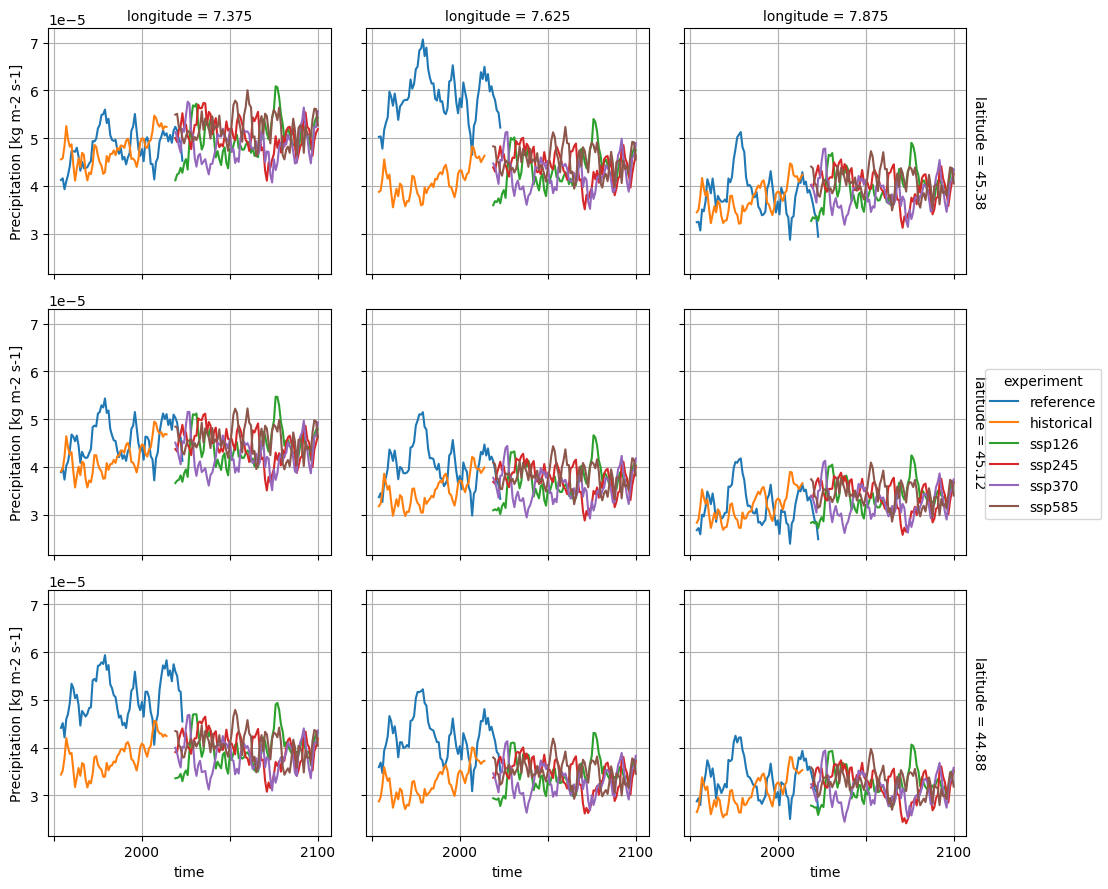

In [9]:
variables = ["pr"]  # Variable tp is present only in ERA5, hence no BA needs to be applied.
for v in variables:
    plots.yearly_mean_time_series_facet(ds_data[v], hue=e_dim, fname=f"adjusted_{v}_{m}_pre.pdf")

Then apply QDM, it would be multiplicative for precipitation, but some quantiles get clipped, hence additive QDM is used.

In [10]:
_da = {}
for v in variables:
    ba[v] = xclim.sdba.QuantileDeltaMapping.train(
        ds_data[v].sel({e_dim: "reference", "time": thesis.training_period}, drop=True),
        ds_data[v].sel({e_dim: "historical", "time": thesis.training_period}, drop=True),
        nquantiles=nquantiles_training,
        group="time",
        kind='+'
    )
    _da[v] = ba[v].adjust(ds_data[v])
    _da[v].name = v  # Overwrite the default name.
ds_adjusted = ds_adjusted.assign(_da)

# Insert the original reference, which is correct by definition.
ds_adjusted = ds_adjusted.drop_sel({e_dim: "reference"})
ds_adjusted = xarray.concat(
    (ds_adjusted, ds_data.sel({e_dim: "reference"})),
    e_dim
)

Plot the results of BA for precipitation.

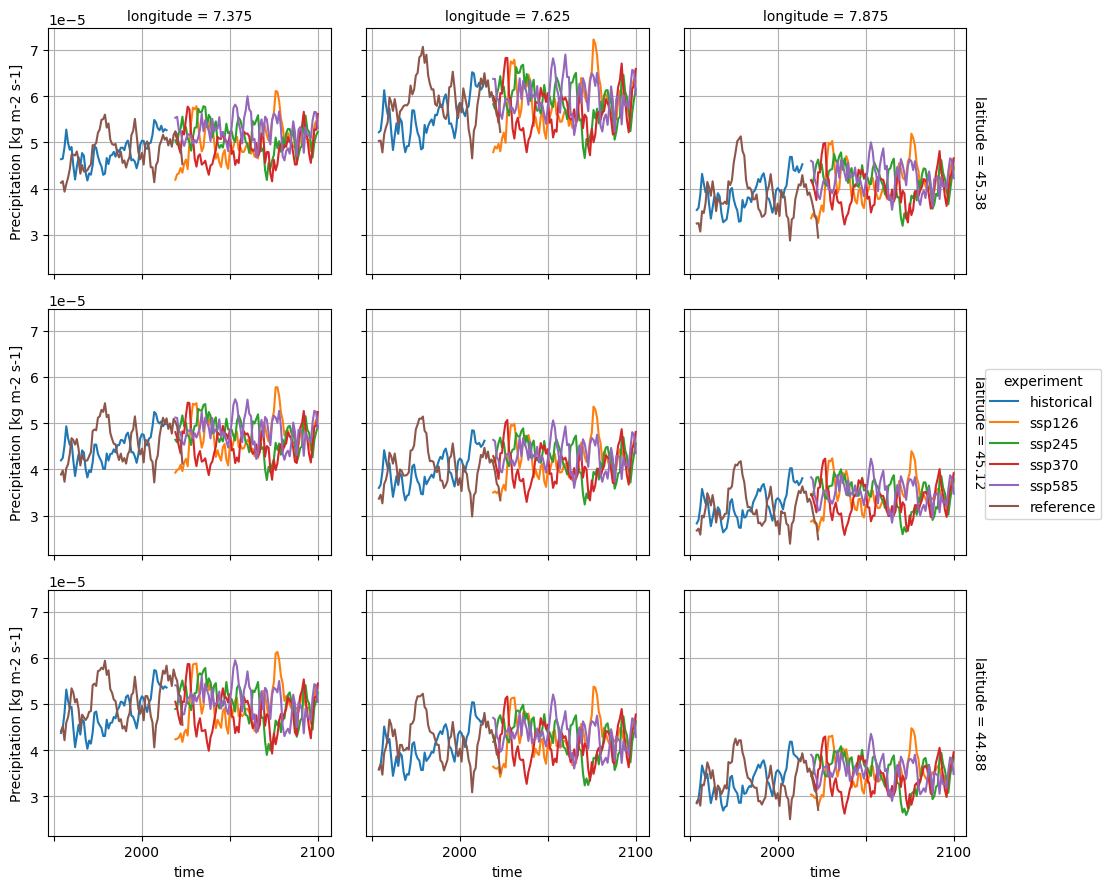

In [11]:
for v in variables:
    plots.yearly_mean_time_series_facet(ds_adjusted[v], hue=e_dim, fname=f"adjusted_{v}_{m}_post.pdf")

Compare pre and post BA time series qualitatively.

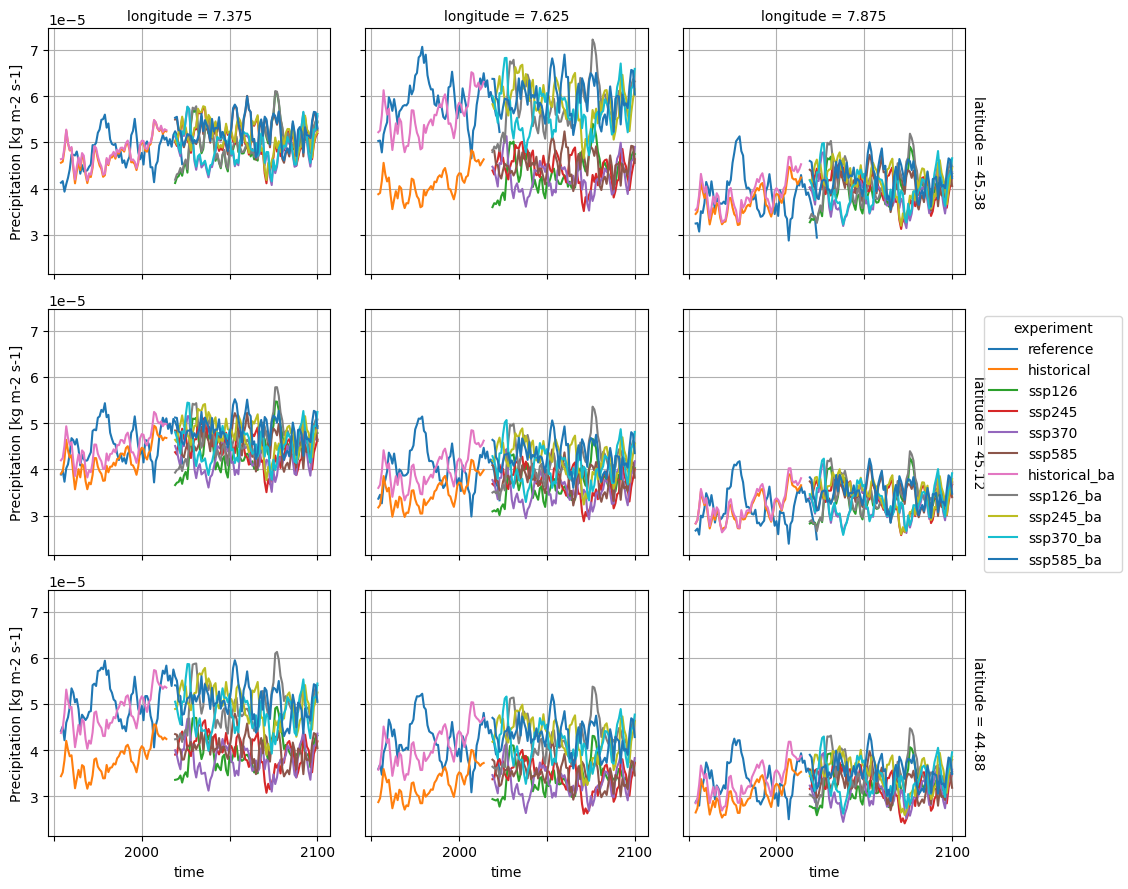

In [12]:
_ds = xarray.concat(
    (ds_data[variables], ds_adjusted[variables].assign_coords({e_dim: ds_adjusted[e_dim].str + "_ba"})),
    e_dim,
    combine_attrs="drop_conflicts"
)
_ds = _ds.drop_sel({e_dim: "reference_ba"})  # Do not plot same time series twice.
for v in variables:
    plots.yearly_mean_time_series_facet(_ds[v], hue=e_dim, fname=f"adjusted_{v}_{m}_prepost.pdf")

## Test BA

Use a period of the historical experiment to show qualitatively the performance of the BA.

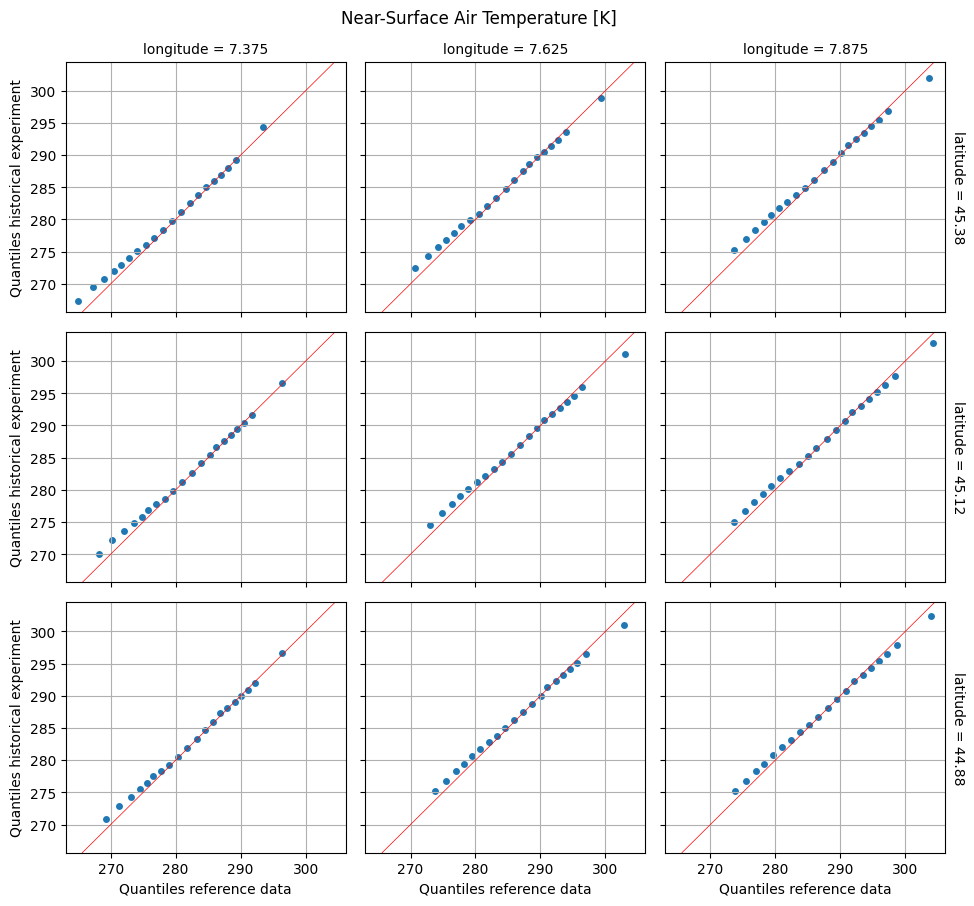

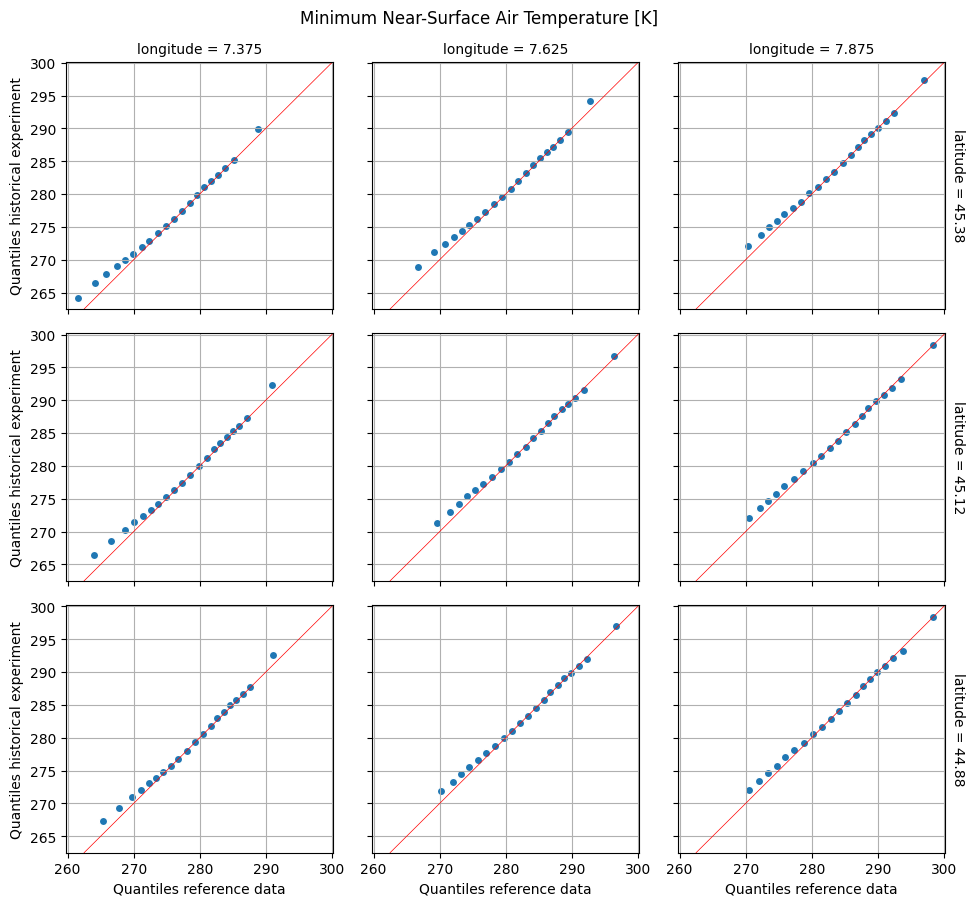

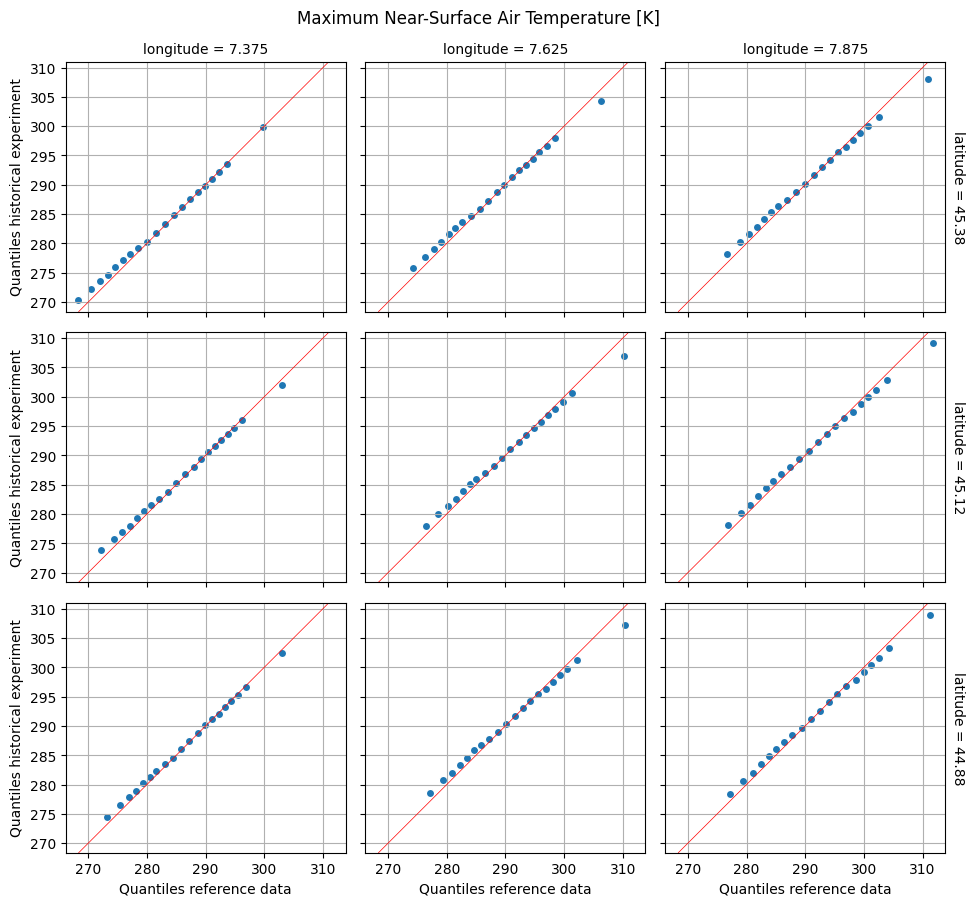

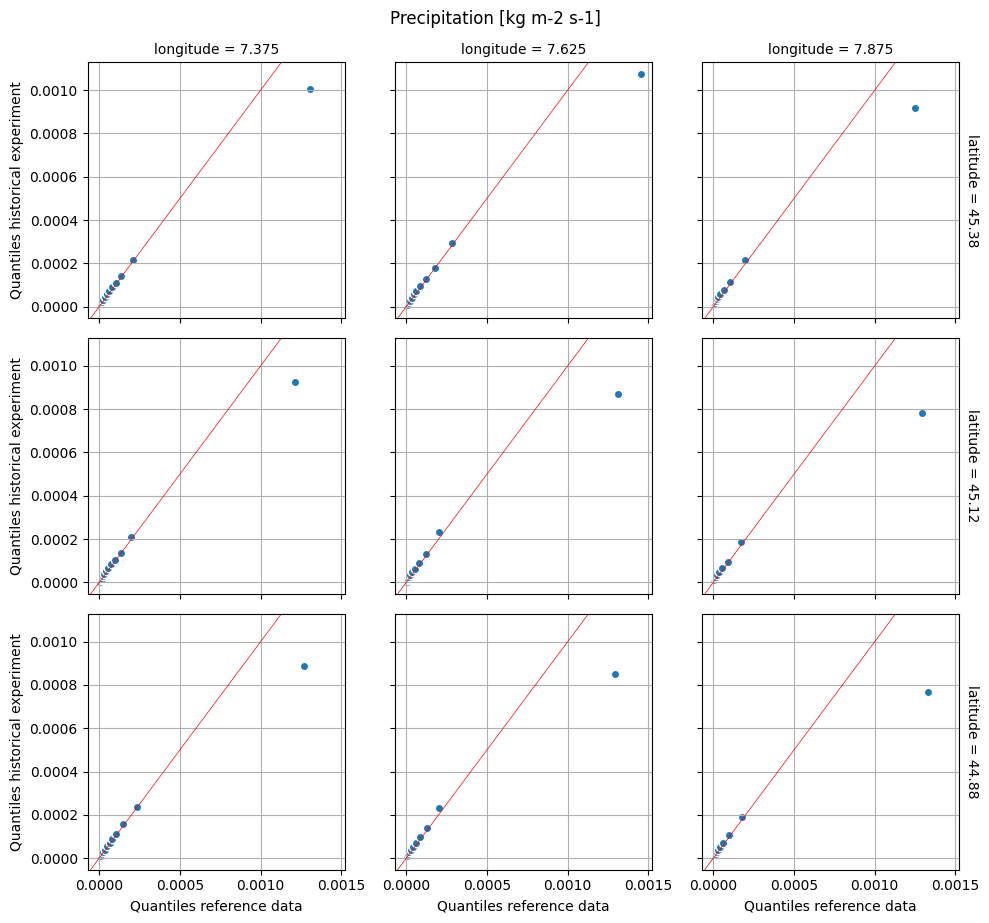

In [13]:
quantiles = numpy.arange(1, nquantiles_test + 1, 1)
quantiles = quantiles / len(quantiles)

_reference = ds_data.sel({e_dim: "reference", "time": thesis.test_period}).quantile(quantiles, dim="time")
_historical = ds_adjusted.sel({e_dim: "historical", "time": thesis.test_period}).quantile(quantiles, dim="time")
_ds = _historical.assign({f"{k}_th": v for k, v in _reference.data_vars.items()})  # Distinguish theoretical quantiles.

for v in ba.keys():
    _plot = plots.scatter_facet(_ds, x=f"{v}_th", y=v)
    _plot.fig.suptitle(f"{_ds[v].attrs['long_name']} [{_ds[v].attrs['units']}]", y=1, verticalalignment="bottom")
    _plot.set_axis_labels("Quantiles reference data", "Quantiles historical experiment")
    for ax in _plot.axs.ravel():
        ax.axline((0,0), slope=1, color="red", linewidth=0.5)
    plots.savefig(f"adjusted_{v}_{m}_test.pdf")

Store the adjusted data in a file for future use.

In [14]:
experiments = list(dict_dataset.keys())
experiments.remove("reference")
for e in experiments:
    path = dir_out / f"{e}_{m}.nc"
    ds_adjusted[list(ba.keys())].sel({e_dim: e}, drop=True).to_netcdf(path)